# Multi-Period Portfolio Optimization via Model-Predictive Control (MPC)

A learning-oriented port of the single-period daily MVO in
`../optimizer/optimal_portfolio.ipynb` to a **multi-period** setting, driven with
**Model-Predictive Control** (a.k.a. *receding-horizon control*).

**The single-period optimizer** (the one we run live) treats each day in isolation: the
book is flat at every close, so it solves one QP for *today's* dollar positions `x`, given
today's alpha / risk / cost. There is no notion of "what will I want to hold tomorrow, and
is it worth paying impact today to get partway there?"

**The multi-period optimizer** plans a whole **trajectory** of holdings
`h_1, h_2, ..., h_H` over the next `H` periods (here: 30-minute bars stretching across the
next few trading days). It trades off, jointly across the horizon:

- the **alpha** it expects to earn each period (which *decays* — a signal is worth more now
  than 5 bars from now),
- the **risk** carried each period,
- the **convex trading cost** of *changing* the book (spread + square-root impact), which
  makes it cheaper to *split* a large rebalance across several periods than to slam it in one.

**MPC** is how you actually *run* a multi-period plan in the face of new information: solve
the `H`-period problem, **execute only the first period's trade**, then step the clock
forward one bar, absorb the new data (fresh alpha forecasts, realized fills), and
**re-solve** over the shifted horizon. You re-plan every bar and only ever commit the next
step. The long plan is a *guide*, not a *commitment*.

> Everything here is **synthetic** — a generic factor covariance and a generic mean-reverting
> alpha — so the notebook is self-contained and the focus stays on *how you build the
> system*, not on the data plumbing. We deliberately reuse the idioms from the optimizer
> notebook: cvxpy + CLARABEL, a factor risk model `Σ = LᵀΣ_f L + D`, a parametrized problem
> **compiled once** and re-solved by setting `cp.Parameter` values, and 3/2-power impact via
> `cp.power(cp.abs(·), 1.5)`.

## From one QP to a trajectory

**Single-period** (the live optimizer, schematically):

$$\max_{x}\; \alpha^\top x \;-\; \tfrac{\lambda}{2}\, x^\top \Sigma\, x \;-\; \text{cost}(x)$$

with `x` the dollar book for the single period.

**Multi-period**: introduce a holding vector $h_t$ for each period $t = 1 \dots H$, and let
the **trade** into period $t$ be

$$u_t \;=\; h_t - h_{t-1}, \qquad h_0 \equiv \text{current holdings (a parameter, not a variable).}$$

Costs are charged on the **trade** $u_t$ (you pay to *change* the book), while alpha and risk
are earned/carried on the **holding** $h_t$:

$$\max_{h_1,\dots,h_H}\;\; \sum_{t=1}^{H}\Big[\; \underbrace{\alpha_t^\top h_t}_{\text{expected PnL}}
\;-\; \underbrace{\tfrac{\lambda}{2}\, h_t^\top \Sigma\, h_t}_{\text{risk}}
\;-\; \underbrace{s^\top |u_t|}_{\text{spread}}
\;-\; \underbrace{\gamma \textstyle\sum_i \eta_i\, |u_{t,i}|^{3/2}}_{\text{sqrt impact}} \;\Big]$$

subject to per-period constraints (leverage / risk cap / factor neutrality / an optional
**terminal** condition like $h_H = 0$ to flatten by end of horizon).

Two things make this *genuinely* multi-period rather than `H` copies of the same problem:

1. **The trade coupling** $u_t = h_t - h_{t-1}$ — periods are chained through the cost term.
   A big move is cheaper split across bars because impact is **convex** ($3/2$ power).
2. **The alpha path** $\alpha_1, \dots, \alpha_H$ — the forecast *decays* over the horizon,
   so the optimizer knows an edge is temporary and won't overpay impact to chase it.

The only parameters that change from one MPC step to the next are **the current holdings
$h_0$** and **the alpha path**. Keeping everything else constant makes the problem
[**DPP**](https://www.cvxpy.org/tutorial/dpp/index.html) — cvxpy compiles the QP once and
each re-solve is a fast parameter swap. That is exactly what you want when you re-solve every
30 minutes.

In [1]:
import numpy as np
import cvxpy as cp
import scipy.linalg
import matplotlib.pyplot as plt

RNG = np.random.default_rng(7)

# ---- problem dimensions -------------------------------------------------------
N = 15                    # names in the (generic) universe
K = 3                     # risk factors
H = 8                     # planning horizon, in 30-min periods (~ a few bars into future days)
PERIODS_PER_DAY = 13      # 30-min bars in a 9:30-16:00 session (for annualization / day marks)

# ---- economic knobs (chosen so the RISK/COST tradeoff binds, not a hard cap) ---
LAMBDA   = 200.0          # risk aversion (per period).  Larger -> smaller, tighter book.
IMPACT_G = 0.08           # scalar square-root-impact coefficient  (gamma ~ O(0..1))
GMV_CAP  = 5.0            # gross-leverage cap per period (units of capital); slack at these knobs
SPREAD   = 3e-4           # half-spread per name (return units), charged on |trade|
IMP_ETA  = 0.30           # per-name impact liquidity coeff eta_i (generic, constant across names)

print(f"N={N} names, K={K} factors, horizon H={H} periods "
      f"(~{H/PERIODS_PER_DAY:.1f} trading days ahead)")

N=15 names, K=3 factors, horizon H=8 periods (~0.6 trading days ahead)


## 1. A generic factor risk model

Same shape as `covariance/covariance.ipynb`: a low-rank **factor covariance**
$\Sigma = L^\top \Sigma_f L + D$ with loadings $L\in\mathbb{R}^{K\times N}$, a factor
covariance $\Sigma_f$, and an idiosyncratic diagonal $D$. We just *generate* it here instead
of estimating it — but we keep the same on-disk-vintage names (`L`, `Sigma_f`, `D`, `Sigma`)
and the same numerically-sparse risk term the live optimizer uses:

$$\sqrt{h^\top \Sigma\, h} \;=\; \Big\| \big[\, \Sigma_f^{1/2} L h \,;\; D^{1/2} h \,\big] \Big\|_2$$

Writing the risk this way (a norm over the *factor* pieces) keeps the QP well-conditioned —
we never form or Cholesky the dense `N×N` `Σ` inside the solver.

In [2]:
# Generic factor covariance (per-period RETURN units).  Purely synthetic but PSD & full-rank,
# exactly the Sigma = L^T Sigma_f L + D structure the live risk model produces.
L       = RNG.normal(0, 1, (K, N)) * 0.010          # factor loadings  (K x N)
SIGMA_F = np.diag([1.0, 0.6, 0.3])                  # factor covariance (K x K), 1st factor "market"
EPS     = (RNG.uniform(0.5, 1.5, N) * 0.004) ** 2   # idiosyncratic variances (per name)
D       = np.diag(EPS)
SIGMA   = L.T @ SIGMA_F @ L + D                      # full name covariance (N x N)

# PSD / conditioning sanity check (same discipline as the covariance notebook)
evals = np.linalg.eigvalsh(SIGMA)
assert evals.min() > 0, "Sigma not PD"
print(f"Sigma PD: min eig = {evals.min():.2e},  condition number = {evals.max()/evals.min():,.0f}")

# Pre-factor the pieces the risk term needs (constants -> keeps the QP DPP).
SIGMA_F_SQRT = scipy.linalg.sqrtm(SIGMA_F).real     # Sigma_f^{1/2}  (K x K)
D_SQRT       = np.sqrt(EPS)                          # D^{1/2} as a vector (N,)
# Cholesky of the full Sigma, used ONLY to draw correlated realized returns in the simulator.
SIGMA_CHOL   = np.linalg.cholesky(SIGMA)


def risk_norm(h):
    """sqrt(h^T Sigma h) written over the factor pieces -> numerically sparse & well-conditioned.
    Accepts a cvxpy expression (for the objective) or a numpy vector (for diagnostics)."""
    if isinstance(h, np.ndarray):
        return float(np.linalg.norm(np.concatenate([SIGMA_F_SQRT @ L @ h, D_SQRT * h])))
    return cp.norm(cp.hstack([SIGMA_F_SQRT @ L @ h, cp.multiply(D_SQRT, h)]), 2)

Sigma PD: min eig = 5.04e-06,  condition number = 239


## 2. A generic alpha with a *forecastable* decay

The whole point of multi-period optimization is that you can **forecast how your signal will
evolve**. If alpha were i.i.d. noise, there would be nothing to plan around — every period
would be independent and the single-period optimizer would be optimal.

So we model the latent signal as a stationary **AR(1)** process per name:

$$s_{t+1} = \rho\, s_t + \varepsilon_t, \qquad \alpha_t = \kappa\, s_t.$$

Because AR(1) is Markov, the forecast at the current bar for $j$ periods ahead is a clean
geometric decay:

$$\mathbb{E}[\alpha_{t+j} \mid s_t] \;=\; \kappa\, \rho^{\,j}\, s_t.$$

That decaying path is what the optimizer plans against: a strong signal *now* is known to fade
with half-life $\ln 2 / \ln(1/\rho)$, so it is not worth paying full impact to chase it all
the way in. `realize()` advances the true latent state one bar and returns the **realized**
per-period return $r_t = \alpha_t + \text{(correlated noise} \sim \mathcal N(0,\Sigma))$ — so
the signal is a genuine (small) predictive edge buried in returns whose covariance is exactly
our risk model `Σ`.

In [3]:
class AlphaSim:
    """Generic mean-reverting alpha. The latent per-name signal s follows a stationary AR(1);
    expected per-period return is kappa*s. Forecasts decay geometrically (rho^j), which is the
    structure the multi-period optimizer plans against. realize() advances the true state one
    bar and returns the realized return (expected alpha + noise correlated by SIGMA)."""

    def __init__(self, rho=0.75, kappa=4e-3):
        self.rho = rho                       # signal persistence (half-life ~ ln2/ln(1/rho) bars)
        self.kappa = kappa                   # signal -> expected-return scale
        self.s = RNG.normal(0.0, 1.0, N)     # latent signal, stationary unit variance

    def forecast(self, horizon):
        """(horizon x N) expected-return path given TODAY's signal: alpha_hat[j] = kappa * rho^j * s.
        Row 0 is the coming period; later rows decay toward 0 -> the edge is temporary."""
        return np.array([self.kappa * (self.rho ** j) * self.s for j in range(horizon)])

    def realize(self):
        """Advance the true signal one bar; return the REALIZED per-period return for the bar we
        were just holding through. exp = forecast()[0]; realized = exp + correlated noise ~ N(0, SIGMA)."""
        exp = self.kappa * self.s
        realized = exp + SIGMA_CHOL @ RNG.normal(0.0, 1.0, N)
        # AR(1) update with stationary innovation variance (keeps Var[s] = 1)
        self.s = self.rho * self.s + np.sqrt(1.0 - self.rho ** 2) * RNG.normal(0.0, 1.0, N)
        return realized


# quick look at the decay of a forecast made at one instant
_demo = AlphaSim()
_fc = _demo.forecast(H)
print("alpha forecast decay (L2 norm of each row, should shrink ~rho^j):")
print("  " + "  ".join(f"{np.linalg.norm(r):.1e}" for r in _fc))

alpha forecast decay (L2 norm of each row, should shrink ~rho^j):
  1.4e-02  1.1e-02  8.0e-03  6.0e-03  4.5e-03  3.4e-03  2.5e-03  1.9e-03


## 3. Costs and impact — charged on the *trade*

Two cost terms, both identical in spirit to the live optimizer, but now applied to each
period's **trade** $u_t = h_t - h_{t-1}$ rather than to a single day's position:

- **Spread** — linear: $s^\top |u_t|$. A fixed per-name half-spread; paying it twice on a
  round trip is what discourages needless churn.
- **Square-root impact** — convex: $\gamma \sum_i \eta_i |u_{t,i}|^{3/2}$. The Almgren/BARRA
  form. Because it is **super-linear in trade size**, splitting one big rebalance across
  several bars is strictly cheaper than doing it in one — this is the microstructural reason
  MPC "eases into" positions instead of jumping.

We keep the microstructure coefficients (`SPREAD`, `IMP_ETA`) **constant** — they describe
the market, not the signal, and holding them fixed is what keeps the problem DPP so each MPC
re-solve stays fast.

In [4]:
def trade_cost(u):
    """Realized dollar cost of a single trade vector u (numpy): linear spread + 3/2-power impact.
    Same functional form the optimizer trades off in its objective, so expected == realized cost."""
    u = np.asarray(u)
    spread_cost = SPREAD * np.abs(u).sum()
    impact_cost = IMPACT_G * np.sum(IMP_ETA * np.abs(u) ** 1.5)
    return spread_cost + impact_cost

# sanity: doing a trade in 2 halves is cheaper than all at once (convex impact)
_big = np.zeros(N); _big[0] = 2.0
print(f"impact of one 2.0 trade : {trade_cost(_big):.4f}")
print(f"impact of two 1.0 trades: {2*trade_cost(_big/2):.4f}   <- cheaper (super-linear cost)")

impact of one 2.0 trade : 0.0685
impact of two 1.0 trades: 0.0486   <- cheaper (super-linear cost)


## 4. The multi-period optimizer

This is the heart of the notebook — the direct analogue of the `Optimizer` class in the
single-period notebook, but now the decision variable is a **list** of `H` holding vectors and
the objective **sums over the horizon**.

Design choices, and why:

- **Variables** `h[0..H-1]` — the planned dollar book at the *end* of each period.
- **Parameters** `h_prev` (current book) and `A[0..H-1]` (the alpha path). *These are the only
  things that change between MPC steps* — everything else (`Σ`, costs, caps) is a constant, so
  the problem is **DPP** and `set_problem()` compiles it **once**. Each `solve()` is a fast
  parameter swap, mirroring the live optimizer's "compile once, re-solve per day" pattern.
- **Trade chaining** `u_t = h[t] - (h_prev if t==0 else h[t-1])` — this is what couples the
  periods; without it you'd just have `H` unrelated single-period problems.
- **Constraints** — a per-period gross-leverage cap (`‖h_t‖₁ ≤ GMV_CAP`), and an *optional*
  **terminal flat** `h[-1] == 0`. The terminal condition is the multi-period way to encode
  "be flat by the close" — the live strategy is intraday-flat, so if your horizon ends at a
  session close you'd turn this on.

You could add the same **factor-neutrality** rows the live optimizer uses
(`h_t @ L[i] == 0`); left off here to keep the generic trajectory easy to read.

In [5]:
class MultiPeriodOptimizer:
    """Multi-period MVO over an H-period horizon, solved as ONE convex program.
    Plans holdings h_1..h_H; charges convex costs on the trades u_t = h_t - h_{t-1}.
    Compiled once (DPP); each solve() only swaps the h_prev and alpha-path parameters."""

    def __init__(self, universe_size: int, horizon: int):
        self.N = universe_size
        self.H = horizon

    def set_problem(self, lam, gamma, spread, imp_eta, gmv_cap, flatten_terminal=False):
        N, H = self.N, self.H
        # -- Variables: one holding vector per period --
        self.h = [cp.Variable(N, name=f"h{t}") for t in range(H)]
        # -- Parameters that change each MPC step: current book + the alpha path --
        self.h_prev = cp.Parameter(N, name="h_prev")
        self.A = [cp.Parameter(N, name=f"alpha{t}") for t in range(H)]

        objective, constraints = 0, []
        for t in range(H):
            h_t = self.h[t]
            u_t = h_t - (self.h_prev if t == 0 else self.h[t - 1])   # trade INTO period t
            # alpha earned on the holding; risk carried on the holding; costs paid on the trade
            objective += (
                self.A[t] @ h_t
                - (lam / 2) * risk_norm(h_t) ** 2                                  # (1/2) lam h'Sigma h
                - spread * cp.sum(cp.abs(u_t))                                     # linear spread
                - gamma * cp.sum(cp.multiply(imp_eta, cp.power(cp.abs(u_t), 1.5))) # 3/2-power impact
            )
            constraints.append(cp.norm(h_t, 1) <= gmv_cap)                         # gross-leverage cap
        if flatten_terminal:
            constraints.append(self.h[-1] == 0)                                    # flat by end of horizon

        self.problem = cp.Problem(cp.Maximize(objective), constraints)
        assert self.problem.is_dcp(dpp=True), "problem is not DPP -> re-solves won't be fast"

    def solve(self, alpha_path: np.ndarray, h_prev: np.ndarray) -> np.ndarray:
        """alpha_path: (H, N) forecast; h_prev: (N,) current book.
        Returns the planned trajectory as an (H, N) array of dollar holdings."""
        self.h_prev.value = h_prev
        for t in range(self.H):
            self.A[t].value = alpha_path[t]
        self.problem.solve(solver=cp.CLARABEL)
        if self.problem.status not in ("optimal", "optimal_inaccurate"):
            raise RuntimeError(self.problem.status)
        return np.array([self.h[t].value for t in range(self.H)])


# compile once, solve once as a smoke test
opt = MultiPeriodOptimizer(N, H)
opt.set_problem(LAMBDA, IMPACT_G, SPREAD, IMP_ETA, GMV_CAP)
_traj = opt.solve(AlphaSim().forecast(H), np.zeros(N))
print("planned GMV per period (from a flat start):",
      "  ".join(f"{np.abs(_traj[t]).sum():.2f}" for t in range(H)))
print("^ ramps IN gradually instead of jumping to the target -> convex impact + decaying alpha")

planned GMV per period (from a flat start): 0.52  0.75  0.84  0.88  0.89  0.89  0.89  0.89
^ ramps IN gradually instead of jumping to the target -> convex impact + decaying alpha


## 5. Model-Predictive Control: the receding-horizon loop

The optimizer above produces a *plan* — a whole trajectory. **MPC** is the discipline for
running that plan when the world keeps changing under you:

```
   state  h  <- current holdings (start flat)
   repeat every bar:
       1. FORECAST : build the H-period alpha path from the latest signal
       2. PLAN     : solve the H-period QP  ->  trajectory  h_1 ... h_H
       3. EXECUTE  : commit ONLY the first step  ->  new book = h_1
       4. REALIZE  : the bar plays out; book earns h_1 . r  minus trade costs
       5. SHIFT    : advance one bar; the horizon slides forward one period
```

The critical idea is step 3: **you throw away $h_2 \dots h_H$.** They were computed only so
that $h_1$ accounts for the future — but next bar you'll have new information, so you re-plan
from scratch. The long tail of the plan is a *lookahead device*, never a commitment. This is
what makes MPC robust: every executed trade is the first step of a fresh, fully-informed
re-optimization.

Note the tight analogy to the live system: the daily orchestrator already re-solves once per
day with fresh data and executes immediately. MPC is the same feedback loop at 30-minute
cadence with a *lookahead horizon* bolted on.

In [6]:
def run_mpc(horizon, n_steps, lam=LAMBDA, gamma=IMPACT_G, gmv_cap=GMV_CAP,
            flatten_terminal=False, record_plans_at=(), seed=None):
    """Run the receding-horizon loop for n_steps bars. Returns a dict of realized time series
    plus (optionally) the full planned trajectories captured at the bars in record_plans_at
    (so we can draw the classic 'plan vs executed' MPC picture).

    Each bar: forecast -> plan H periods -> EXECUTE only step 0 -> realize PnL -> shift.
    Pass `seed` to reseed the alpha/return draws for an independent path (the MARKET -- L, SIGMA --
    stays fixed; only the signal realization changes), used to average the horizon sweep below."""
    global RNG
    if seed is not None:
        RNG = np.random.default_rng(seed)
    alpha = AlphaSim()
    opt = MultiPeriodOptimizer(N, horizon)
    opt.set_problem(lam, gamma, SPREAD, IMP_ETA, gmv_cap, flatten_terminal)

    h = np.zeros(N)                          # current book (start flat)
    hold_hist, gmv, turn, pnl, cost = [], [], [], [], []
    plans = {}

    for k in range(n_steps):
        traj = opt.solve(alpha.forecast(horizon), h)   # PLAN the whole horizon
        if k in record_plans_at:
            plans[k] = (h.copy(), traj.copy())         # stash plan for the MPC diagram
        h_next = traj[0]                               # EXECUTE only the first step
        u = h_next - h                                 # the trade we actually send
        c = trade_cost(u)
        r = alpha.realize()                            # the bar plays out
        step_pnl = float(h_next @ r - c)               # hold h_next through the bar, net of cost

        hold_hist.append(h_next.copy())
        gmv.append(np.abs(h_next).sum()); turn.append(np.abs(u).sum())
        pnl.append(step_pnl); cost.append(c)
        h = h_next                                     # SHIFT: carry the book to the next bar

    ann = np.sqrt(PERIODS_PER_DAY * 252)               # per-bar -> annualized
    pnl = np.array(pnl)
    return dict(
        holdings=np.array(hold_hist), gmv=np.array(gmv), turnover=np.array(turn),
        pnl=pnl, cost=np.array(cost), cum_pnl=np.cumsum(pnl), plans=plans,
        sharpe=float(pnl.mean() / pnl.std() * ann) if pnl.std() > 0 else np.nan,
    )

## 6. Run one simulation

Let's run the full loop and look at the headline numbers. We capture the plans at a few
consecutive bars so we can draw the receding horizon afterward.

In [7]:
T_SIM = 150                                     # ~11.5 trading days of 30-min bars
PLAN_WINDOW = tuple(range(40, 46))             # capture 6 consecutive plans for the MPC diagram

res = run_mpc(H, T_SIM, record_plans_at=PLAN_WINDOW)

print(f"horizon H = {H} periods,  {T_SIM} bars simulated")
print(f"  cumulative net PnL : {res['cum_pnl'][-1]:+.3f}   (units of capital)")
print(f"  mean daily GMV     : {res['gmv'].mean():.2f}")
print(f"  mean bar turnover  : {res['turnover'].mean():.3f}")
print(f"  total trading cost : {res['cost'].sum():.3f}")
print(f"  annualized Sharpe  : {res['sharpe']:.1f}")

horizon H = 8 periods,  150 bars simulated
  cumulative net PnL : +1.139   (units of capital)
  mean daily GMV     : 4.51
  mean bar turnover  : 0.753
  total trading cost : 0.923
  annualized Sharpe  : 47.2


## 7. Visualizing the receding horizon

The signature MPC picture. At each of several consecutive bars we drew a *plan* — a dashed
GMV trajectory reaching `H` bars into the future. But we only ever **executed the first step**
of each (the solid line threads through the first point of every plan). Watch how each new
plan revises the previous one as fresh information arrives: the dashed tails fan out, but the
committed path is a single continuous thread of first-steps.

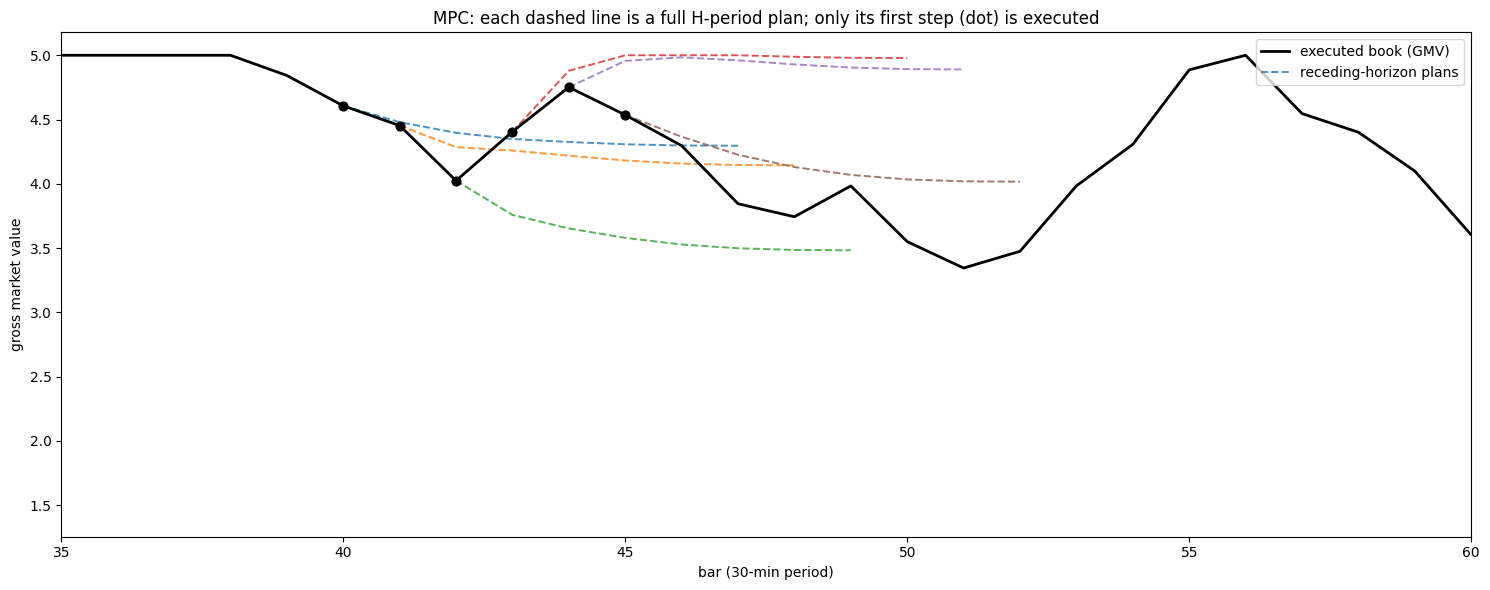

In [8]:
fig, ax = plt.subplots(figsize=(15, 6))

# solid: the actually-EXECUTED gross-market-value path (first step of each re-solve)
ax.plot(range(T_SIM), res["gmv"], color="black", lw=2.0, zorder=5, label="executed book (GMV)")

# dashed: the PLANNED trajectory drawn at each captured bar -> only its first point is executed
for j, (k, (h0, traj)) in enumerate(res["plans"].items()):
    xs = range(k, k + H)
    plan_gmv = [np.abs(traj[t]).sum() for t in range(H)]
    ax.plot(xs, plan_gmv, "--", lw=1.4, alpha=0.8,
            label="receding-horizon plans" if j == 0 else None)
    ax.scatter([k], [plan_gmv[0]], s=40, zorder=6, color="black")  # the committed first step

ax.set_xlim(35, 60)
ax.set_xlabel("bar (30-min period)"); ax.set_ylabel("gross market value")
ax.set_title("MPC: each dashed line is a full H-period plan; only its first step (dot) is executed")
ax.legend(loc="upper right"); fig.tight_layout(); plt.show()

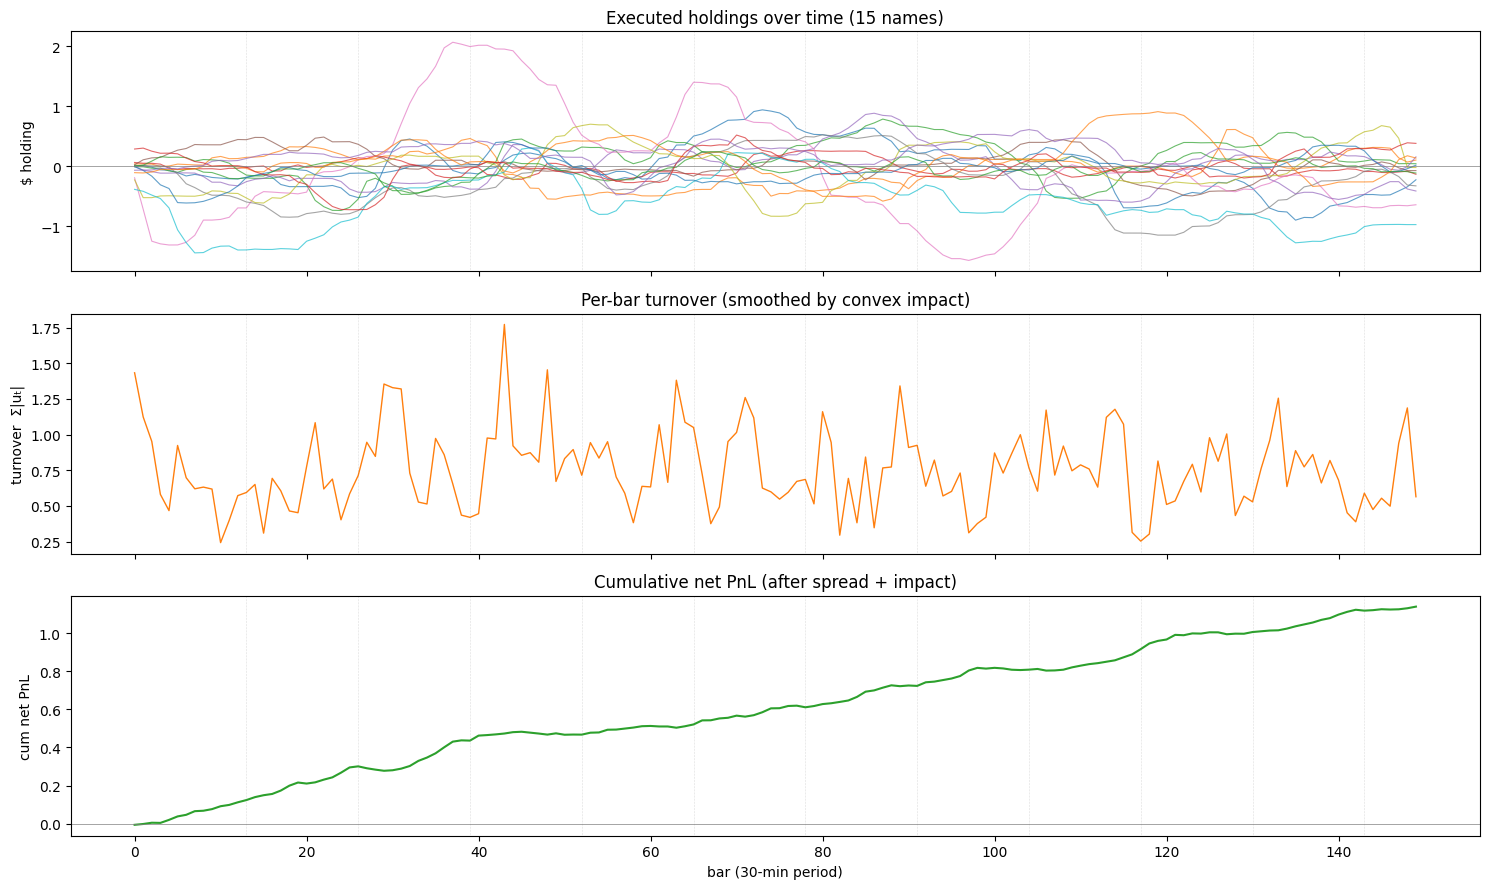

In [9]:
# Executed book over the whole sim: holdings (one line per name), turnover, cumulative PnL.
fig, (ax_h, ax_t, ax_p) = plt.subplots(3, 1, figsize=(15, 9), sharex=True)

for i in range(N):
    ax_h.plot(res["holdings"][:, i], lw=0.8, alpha=0.7)
ax_h.axhline(0, color="grey", lw=0.5)
ax_h.set_ylabel("$ holding"); ax_h.set_title(f"Executed holdings over time ({N} names)")

ax_t.plot(res["turnover"], color="tab:orange", lw=1.0)
ax_t.set_ylabel("turnover  Σ|uₜ|"); ax_t.set_title("Per-bar turnover (smoothed by convex impact)")

ax_p.plot(res["cum_pnl"], color="tab:green", lw=1.5)
ax_p.axhline(0, color="grey", lw=0.5)
ax_p.set_ylabel("cum net PnL"); ax_p.set_xlabel("bar (30-min period)")
ax_p.set_title("Cumulative net PnL (after spread + impact)")

# light day boundaries
for d in range(PERIODS_PER_DAY, T_SIM, PERIODS_PER_DAY):
    for ax in (ax_h, ax_t, ax_p):
        ax.axvline(d, color="grey", lw=0.4, ls=":", alpha=0.5)

fig.tight_layout(); plt.show()

## 8. Why look ahead at all? Single-period vs multi-period

The cleanest way to see the value of the horizon is to sweep it. `H = 1` **is** the myopic
single-period optimizer — it re-solves every bar (so it still gets MPC's feedback), but it
sees only *one* period of alpha and has no reason to pre-position. Larger `H` lets the
optimizer act on the *whole decaying alpha path* and amortize convex impact across bars.

With a fast-decaying signal like ours, looking ahead lets the book carry more of the edge
while it lasts, so net-of-cost PnL and Sharpe improve as `H` grows — with diminishing returns
once `H` covers the signal's half-life (there's nothing left to forecast beyond that).

A single simulated path is noisy, so we **average each horizon over many independent alpha
paths** (same fixed market `L`, `Σ`; only the signal realization is reseeded). That's the
honest way to read a backtest knob — one path can rank `H=4` below `H=2` by luck.

In [10]:
horizons = [1, 2, 4, 6, 8, 12]
SEEDS = range(16)                              # independent alpha paths per horizon

# runs[h] = list of result dicts, one per seed
runs = {h: [run_mpc(h, T_SIM, seed=sd) for sd in SEEDS] for h in horizons}

def agg(h, key):
    vals = np.array([(r["cum_pnl"][-1] if key == "cum_pnl" else
                      r["cost"].sum()    if key == "cost"    else
                      r[key]) for r in runs[h]])
    return vals.mean(), vals.std()

print(f"{'H':>3} {'cumPnL(mean±sd)':>18} {'Sharpe(mean±sd)':>18} {'totCost':>9} {'meanTurn':>9}")
for h in horizons:
    pm, ps = agg(h, "cum_pnl"); sm, ss = agg(h, "sharpe"); cm, _ = agg(h, "cost")
    tm = np.mean([r["turnover"].mean() for r in runs[h]])
    print(f"{h:>3} {pm:>+9.3f} ±{ps:5.3f} {sm:>9.1f} ±{ss:5.1f} {cm:>9.3f} {tm:>9.3f}")

  H    cumPnL(mean±sd)    Sharpe(mean±sd)   totCost  meanTurn
  1    +0.385 ±0.146      31.0 ±  9.4     0.076     0.130
  2    +0.794 ±0.236      38.9 ±  9.7     0.308     0.348
  4    +1.029 ±0.233      44.4 ±  8.4     0.707     0.622
  6    +1.034 ±0.232      44.2 ±  8.2     0.879     0.726
  8    +1.011 ±0.231      44.1 ±  8.1     0.919     0.750
 12    +0.943 ±0.220      45.3 ±  7.7     0.851     0.712


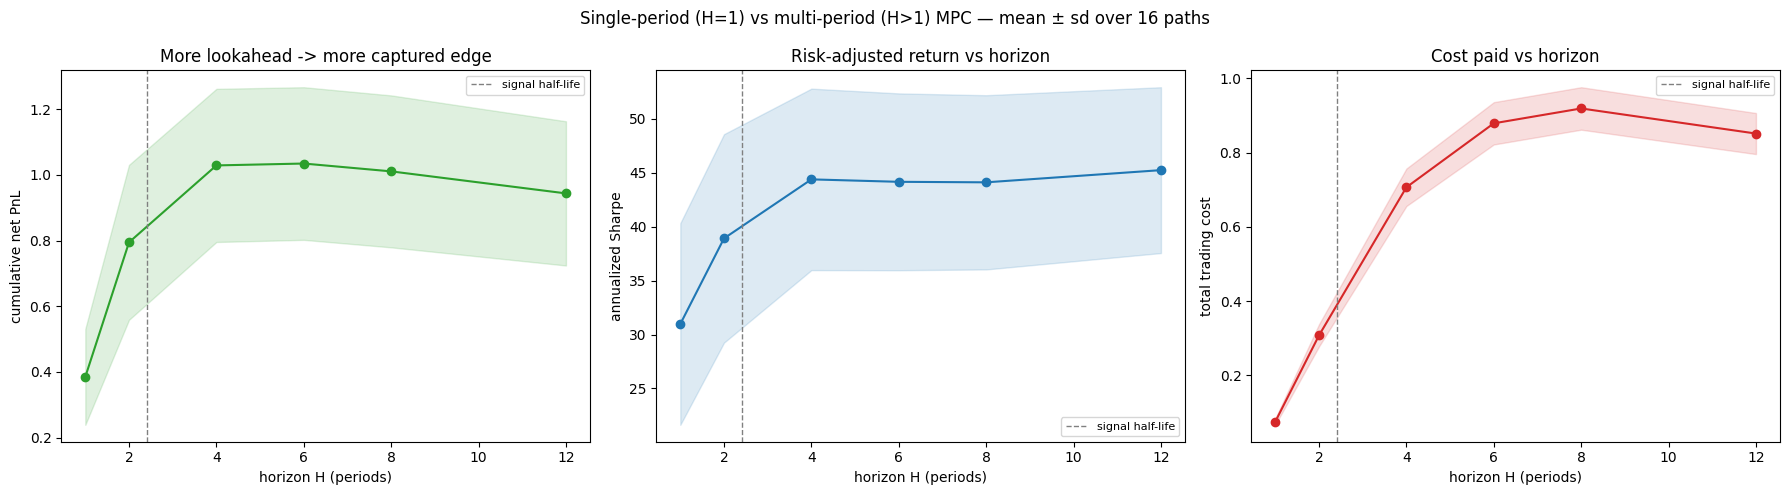

In [11]:
fig, (ax_p, ax_s, ax_c) = plt.subplots(1, 3, figsize=(18, 5))

def band(ax, key, color, ylabel, title):
    m = np.array([agg(h, key)[0] for h in horizons])
    s = np.array([agg(h, key)[1] for h in horizons])
    ax.plot(horizons, m, "o-", color=color)
    ax.fill_between(horizons, m - s, m + s, color=color, alpha=0.15)  # ±1 sd across paths
    ax.set_xlabel("horizon H (periods)"); ax.set_ylabel(ylabel); ax.set_title(title)

band(ax_p, "cum_pnl", "tab:green", "cumulative net PnL", "More lookahead -> more captured edge")
band(ax_s, "sharpe",  "tab:blue",  "annualized Sharpe",  "Risk-adjusted return vs horizon")
band(ax_c, "cost",    "tab:red",   "total trading cost", "Cost paid vs horizon")

for ax in (ax_p, ax_s, ax_c):
    ax.axvline(np.log(2)/np.log(1/0.75), color="grey", ls="--", lw=1, label="signal half-life")
    ax.legend(fontsize=8)
fig.suptitle(f"Single-period (H=1) vs multi-period (H>1) MPC — mean ± sd over {len(list(SEEDS))} paths")
fig.tight_layout(); plt.show()

## 9. Notes, variants, and how this maps to the live system

**What you just built.** A receding-horizon controller: plan `H` periods with one convex
program, execute one step, absorb new data, re-plan. The multi-period QP is a near drop-in
generalization of the single-period `Optimizer` — same factor risk model, same 3/2-power
impact, same "compile once, re-solve by swapping parameters" (kept DPP by holding
microstructure constant and parameterizing only the two things that actually change: current
holdings and the alpha path).

**Variants worth trying** (small edits from here):

- **Terminal flat for an intraday book.** Set `flatten_terminal=True` and align the horizon
  end with a session close to reproduce the live strategy's *flat-by-16:00* behavior — the
  optimizer then *plans its own exit*, unwinding gradually to dodge impact instead of dumping
  at the bell. (Handling *multiple* day-closes inside one horizon means a terminal constraint
  at each close index — a short extension of the constraint loop.)
- **Factor / market neutrality.** Add the live optimizer's rows `h_t @ L[i] == 0` per period.
- **A risk *cap* instead of a penalty.** Swap the `‖h_t‖₁` cap for `risk_norm(h_t) <= vol_cap`
  — the exact SOC constraint the live optimizer uses — to target a dollar-vol budget per bar.
- **Time-varying microstructure.** If ADV/vol should vary by period (they do — the U-shaped
  intraday volume curve), make `spread`/`imp_eta` **parameters** again. That breaks DPP, so
  re-solves recompile; usually still fast enough at 30-min cadence, and the live single-period
  optimizer already accepts that tradeoff for its per-day impact coefficient.
- **Uncertainty in the plan.** Real MPC often discounts far-horizon alpha (it's noisier) or
  shrinks $\alpha_t$ by a confidence that falls with $t$ — a one-line change to `forecast()`.

**The honest caveat.** Multi-period optimization is only as good as your ability to *forecast
the alpha path*. Here we handed the optimizer the true AR(1) decay. In production the horizon
forecast is itself a model (how does the close-imbalance signal decay intraday?), and a wrong
decay assumption can make the lookahead worse than myopic. The single-period optimizer's
virtue is that it makes **no** inter-temporal forecast at all. Multi-period earns its keep
exactly when you have a *credible* view of how your edge and your costs evolve over the next
few bars — which, for an intraday auction-imbalance strategy trading toward a known close, is
a very reasonable thing to have.